# Dar_014 — Rule readiness, geometry-only sample runs and study-model sensitivity

**Scope:** work only with existing datasets, KIV authentication-gated sources, and report
which of the proposed power/thermal/radiation/communication checks are actually supported.
No mission dates, battery capacities, hardware response, limits or allowable outages are invented.

Numerically explore the **existing Dar_010 reference-sphere benchmark** and **existing
Dar_005 published profiles**. Neither is relabelled as the user's mission or equipment.
Joint feature tables and uncertainty results come from Dar_012/013.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA=ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import (CONTEXT,PREDICTORS,BLOCK_KEYS,accepted_input,assign_blocks,spatial_blocks,
    validate_observations,distinct_context,context_features,thermal_features,phase_metadata,
    complete_phase_table,block_coverage,pairwise_spearman,sampled_condition_runs)
import decision_eda
def short(region):return region.split('_',2)[-1].replace('_',' ')
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def findings(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)

## Meaning of the temporal and rule outputs
- Count simultaneous **sampled** Sun/Earth center-above-reference-horizon states, not
  simultaneous surface illumination and radio service. The source benchmark has no terrain
  horizons, solar-disc integration or link budget.
- A run of N hourly true samples spans **N−1 hours from first to last sample**. Preserve
  missing samples/time gaps and boundary censoring. These spans are not continuous darkness
  or communication-outage durations; never compare them to an invented battery capacity.
- Published study scenario ratios and depth-profile monotonicity are sensitivity diagnostics,
  not project-specific crew dose or approved protection limits.
- Applicability, mandatory/preference classification and equipment margins remain Unknown
  without a mission/equipment profile. Candidate scores remain null, not zero. No ranking.

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab
Accepted local analysis/dar_013_feature_sensitivity run: 20261106T134244275613Z_b3888b
Accepted local analysis/dar_010_research_geometry run: 20261109T142644587403Z_2ca66b
Accepted local analysis/dar_005_research_radiation run: 20261107T160219935579Z_f7779c


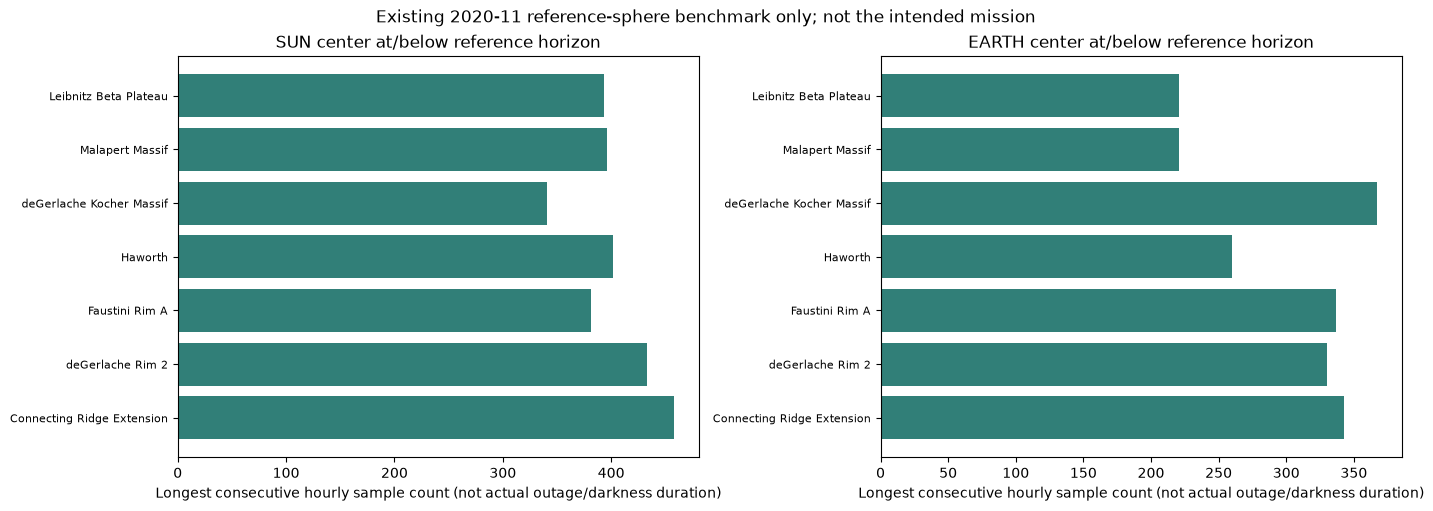

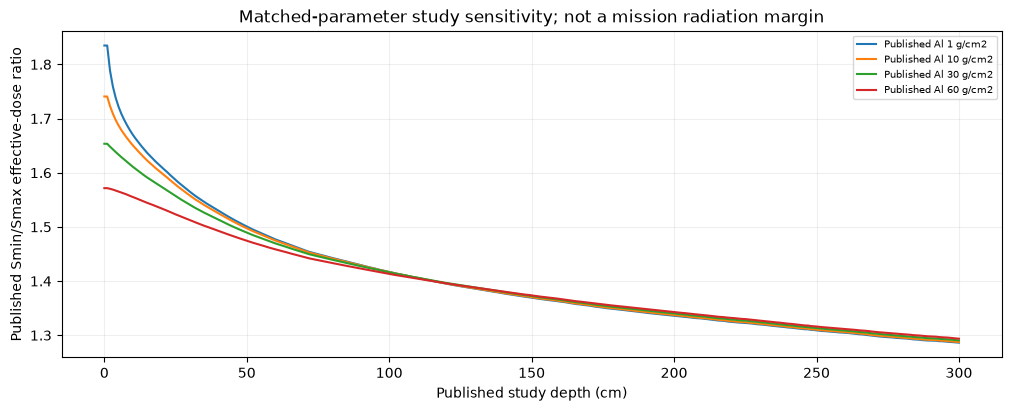

{'regions': 7,
 'reference_geometry_samples_per_region': 720,
 'reference_geometry_run_records': 25,
 'censored_reference_runs': 17,
 'published_all_particle_profiles': 8,
 'profiles_with_some_adjacent_depth_increases': 8,
 'study_Smin_to_Smax_ratio_range': [1.2863339593954028, 1.8347631347671496],
 'potential_region_rule_checks': 28,
 'Unknown_rule_checks': 28,
 'preference_scores_computed': 0,
 'KIV_authenticated_P1_sources': {'D21': 'Chandrayaan-3 ChaSTE surface/subsurface thermal observations',
  'D23': 'Chandrayaan-3 ILSA surface vibration observations'},
 'mission_profile_supplied': False,
 'joint_context_finding': {'selected_regions': 7,
  'selected_products': 144,
  'common_products': 17,
  'observed_native_centers': 55380,
  'usable_center_product_rows': 4825369,
  'indexed_blocks': 2430,
  'blocks_without_observed_centers': 17,
  'candidate_phase_rows': 349920,
  'empty_candidate_phase_rows': 132244,
  'blocks_with_all_common_products_somewhere': 524,
  'blocks_with_fixed_com

,region,target_center,reference_samples,samples_at_or_below_reference_horizon,sample_runs,longest_run_samples,longest_first_to_last_sample_span_hours,longest_left_censored,longest_right_censored
0,A3CLR22_10_Leibnitz_Beta_Plateau,SUN,720,393,1,393,392.0,False,False
1,A3CLR22_10_Leibnitz_Beta_Plateau,EARTH,720,233,2,221,220.0,False,False
2,A3CLR22_11_Malapert_Massif,SUN,720,396,1,396,395.0,False,False
3,A3CLR22_11_Malapert_Massif,EARTH,720,229,2,221,220.0,False,False
4,A3CLR22_12_deGerlache_Kocher_Massif,SUN,720,411,2,341,340.0,False,True
5,A3CLR22_12_deGerlache_Kocher_Massif,EARTH,720,472,2,367,366.0,False,True
6,A3CLR22_2_Haworth,SUN,720,402,1,402,401.0,False,False
7,A3CLR22_2_Haworth,EARTH,720,287,2,260,259.0,False,False
8,A3CLR22_3_Faustini_Rim_A,SUN,720,421,2,381,380.0,True,False
9,A3CLR22_3_Faustini_Rim_A,EARTH,720,421,2,337,336.0,False,True


,al_g_cm2,solar_scenario,tabulated_depth_points,adjacent_depth_increases,adjacent_depth_decreases,largest_adjacent_increase_cSv_year,depth_of_tabulated_maximum_cm,tabulated_maximum_cSv_year
0,1,Smax2015,301,33,267,0.2418,39.0,25.2961
1,1,Smin2019,301,26,274,0.2606,0.0,41.1292
2,10,Smax2015,301,34,265,0.2543,38.0,24.8135
3,10,Smin2019,301,29,271,0.2982,34.0,38.1746
4,30,Smax2015,301,33,267,0.2638,34.0,24.2438
5,30,Smin2019,301,29,271,0.3372,30.0,37.1746
6,60,Smax2015,301,28,272,0.2129,29.0,23.8276
7,60,Smin2019,301,24,276,0.3019,26.0,36.1861


,analysis,environmental_result,mission_check
0,power endurance,static solar context and sampled reference-geo...,Unknown: no actual dated shadow/power model or...
1,thermal capability,joint phase-average thermal/context tables and...,Unknown: component-response/limit evidence mis...
2,radiation protection,"published-model parameter/depth sensitivity, s...",Unknown: no applicable project transport/prote...
3,joint conditions,"co-located descriptive fields, empty phases an...",No eligibility thresholds or usable area inferred
4,communications,mean Earth-visibility context and reference-ge...,Unknown: link/relay/requirements absent
5,uncertainty and redundancy,"same-product cohort, quality-band and spatial-...",No mission ranking or automatic weights/rule r...


,region,potential_rule,constraint_status,reason
0,A3CLR22_10_Leibnitz_Beta_Plateau,power_endurance,Unknown,Actual load/generation/storage parameters and ...
1,A3CLR22_11_Malapert_Massif,power_endurance,Unknown,Actual load/generation/storage parameters and ...
2,A3CLR22_12_deGerlache_Kocher_Massif,power_endurance,Unknown,Actual load/generation/storage parameters and ...
3,A3CLR22_2_Haworth,power_endurance,Unknown,Actual load/generation/storage parameters and ...
4,A3CLR22_3_Faustini_Rim_A,power_endurance,Unknown,Actual load/generation/storage parameters and ...
5,A3CLR22_4_deGerlache_Rim_2,power_endurance,Unknown,Actual load/generation/storage parameters and ...
6,A3CLR22_5_Connecting_Ridge_Extension,power_endurance,Unknown,Actual load/generation/storage parameters and ...
7,A3CLR22_10_Leibnitz_Beta_Plateau,thermal_equipment_margin,Unknown,Component response/test records and equipment ...
8,A3CLR22_11_Malapert_Massif,thermal_equipment_margin,Unknown,Component response/test records and equipment ...
9,A3CLR22_12_deGerlache_Kocher_Massif,thermal_equipment_margin,Unknown,Component response/test records and equipment ...


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_014_rule_readiness\20261109T142703980770Z_b403d6


In [2]:
import csv
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment')
sensitivity=latest_completed_run(ROOT,'analysis/dar_013_feature_sensitivity')
sensitivity_config=json.loads((sensitivity/'provenance.json').read_text())['config']
if (ROOT/sensitivity_config['joint_run']).resolve()!=joint.resolve():
    raise ValueError('Sensitivity and joint studies use different source runs; rerun Dar_013 first')
geometry_run=latest_completed_run(ROOT,'analysis/dar_010_research_geometry')
radiation_run=latest_completed_run(ROOT,'analysis/dar_005_research_radiation')
register=ROOT/'darrel stuff/research/environmental_data.csv'
with Run(ROOT,'analysis/dar_014_rule_readiness',{'joint_run':str(joint.relative_to(ROOT)),
    'sensitivity_run':str(sensitivity.relative_to(ROOT)),'geometry_run':str(geometry_run.relative_to(ROOT)),
    'radiation_run':str(radiation_run.relative_to(ROOT)),'scope':'existing evidence only; no mission or equipment defaults'},'Moon/Environmental_Context/Dar_014_rule_readiness_geometry_context.ipynb') as run:
    run.input(Path(decision_eda.__file__));run.input(register)
    joint_features=pd.read_csv(accepted_input(run,joint,'region_phase_features.csv'))
    joint_findings=json.loads(accepted_input(run,joint,'findings.json').read_text())
    sensitivity_findings=json.loads(accepted_input(run,sensitivity,'findings.json').read_text())
    regions=sorted(joint_features.region.unique())
    geometry=pd.read_csv(accepted_input(run,geometry_run,'reference_sphere_sun_earth_geometry.csv'))
    geometry=geometry.loc[geometry.region.isin(regions)].copy();geometry['utc']=pd.to_datetime(geometry.utc,utc=True)
    if geometry.duplicated(['region','target','utc']).any():raise ValueError('Repeated reference-geometry sample')
    if set(geometry.target)!={'SUN','EARTH'}:raise ValueError('Unexpected reference-geometry targets')
    wide=geometry.pivot(index=['region','utc'],columns='target',values='reference_sphere_center_elevation_deg').reset_index()
    if not np.isfinite(wide[['SUN','EARTH']].to_numpy()).all():raise ValueError('Missing geometry target sample')
    wide['sun_center_above_reference']=wide.SUN.gt(0);wide['earth_center_above_reference']=wide.EARTH.gt(0)
    wide['sampled_state']=np.select([wide.sun_center_above_reference&wide.earth_center_above_reference,
        wide.sun_center_above_reference,wide.earth_center_above_reference],['both_above','sun_only_above','earth_only_above'],default='both_at_or_below')
    wide.to_csv(run.path('reference_geometry_cooccurrence.csv'),index=False)
    states=wide.groupby(['region','sampled_state']).size().rename('sample_count').reset_index()
    states['fraction_of_reference_samples']=states.sample_count/states.groupby('region').sample_count.transform('sum')
    states.to_csv(run.path('reference_geometry_state_counts.csv'),index=False)
    runs=[];summaries=[]
    for region,part in wide.groupby('region'):
        part=part.sort_values('utc')
        for target in ['SUN','EARTH']:
            condition=part[target].le(0)
            intervals=sampled_condition_runs(part.utc,condition,3600)
            intervals['region']=region;intervals['target_center']=target;runs.append(intervals)
            longest=intervals.sort_values(['sample_count','first_sample_utc'],ascending=[False,True]).iloc[0] if len(intervals) else None
            summaries.append({'region':region,'target_center':target,'reference_samples':len(part),
                'samples_at_or_below_reference_horizon':int(condition.sum()),'sample_runs':len(intervals),
                'longest_run_samples':int(longest.sample_count) if longest is not None else 0,
                'longest_first_to_last_sample_span_hours':float(longest.first_to_last_sample_span_hours) if longest is not None else np.nan,
                'longest_left_censored':bool(longest.left_censored) if longest is not None else None,
                'longest_right_censored':bool(longest.right_censored) if longest is not None else None})
    run_table=pd.concat(runs,ignore_index=True);run_summary=pd.DataFrame(summaries)
    run_table.to_csv(run.path('reference_horizon_sample_runs.csv'),index=False)
    run_summary.to_csv(run.path('reference_horizon_run_summary.csv'),index=False)
    fig,axes=plt.subplots(1,2,figsize=(14,5),layout='constrained')
    for ax,target in zip(axes,['SUN','EARTH']):
        part=run_summary.loc[run_summary.target_center.eq(target)]
        ax.barh(range(len(part)),part.longest_run_samples,color='#317f78')
        ax.set_yticks(range(len(part)),[short(x) for x in part.region],fontsize=8)
        ax.set(title=f'{target} center at/below reference horizon',xlabel='Longest consecutive hourly sample count (not actual outage/darkness duration)')
        ax.invert_yaxis()
    fig.suptitle('Existing 2020-11 reference-sphere benchmark only; not the intended mission')
    savefig(run,fig,'reference_sample_runs')
    profiles=pd.read_csv(accepted_input(run,radiation_run,'published_dose_depth_scenarios.csv'))
    profiles=profiles.loc[profiles.particles.eq('all')].copy()
    if profiles.duplicated(['al_g_cm2','solar_scenario','depth_cm']).any():raise ValueError('Duplicate published model point')
    matched=profiles.pivot(index=['al_g_cm2','depth_cm'],columns='solar_scenario',values='effective_dose_cSv_year').reset_index()
    if not {'Smax2015','Smin2019'}.issubset(matched):raise ValueError('Unexpected published solar scenarios')
    matched['published_Smin_to_Smax_ratio']=matched.Smin2019/matched.Smax2015.replace(0,np.nan)
    matched.to_csv(run.path('published_solar_scenario_sensitivity.csv'),index=False)
    profile_shapes=[]
    for (al,solar),part in profiles.groupby(['al_g_cm2','solar_scenario']):
        part=part.sort_values('depth_cm');delta=part.effective_dose_cSv_year.diff();peak=part.loc[part.effective_dose_cSv_year.idxmax()]
        profile_shapes.append({'al_g_cm2':al,'solar_scenario':solar,'tabulated_depth_points':len(part),
            'adjacent_depth_increases':int(delta.gt(0).sum()),'adjacent_depth_decreases':int(delta.lt(0).sum()),
            'largest_adjacent_increase_cSv_year':float(delta.max()),'depth_of_tabulated_maximum_cm':float(peak.depth_cm),
            'tabulated_maximum_cSv_year':float(peak.effective_dose_cSv_year)})
    shapes=pd.DataFrame(profile_shapes);shapes.to_csv(run.path('published_depth_profile_shapes.csv'),index=False)
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    for al,part in matched.groupby('al_g_cm2'):ax.plot(part.depth_cm,part.published_Smin_to_Smax_ratio,label=f'Published Al {al:g} g/cm2')
    ax.set(xlabel='Published study depth (cm)',ylabel='Published Smin/Smax effective-dose ratio',title='Matched-parameter study sensitivity; not a mission radiation margin')
    ax.legend(fontsize=7);ax.grid(alpha=.2);savefig(run,fig,'published_scenario_sensitivity')
    entries={row['Priority ID'].split()[0].split('-')[1]:row for row in csv.DictReader(register.open(encoding='utf-8-sig'))}
    dependencies={
        'power_endurance':(['M04','M07'],'Actual load/generation/storage parameters and dated terrain-aware illumination history are absent'),
        'thermal_equipment_margin':(['M01','M04'],'Component response/test records and equipment limits are absent; surface tbol is not component temperature'),
        'radiation_protection_margin':(['M04','M06'],'Applicable transport/protection results and mission/equipment requirements are absent; orbital/study proxies are not crew surface dose'),
        'communications_continuity':(['M04','M08'],'Antenna/relay/link budget and acceptable outage requirements are absent; reference-center geometry is not radio service')}
    checks=[]
    for rule,(required,reason) in dependencies.items():
        for key in required:
            if key not in entries or 'not supplied' not in entries[key]['Data Readiness'].lower():
                raise ValueError(f'Register now records different project readiness for {key}; explicitly configure its actual inputs before evaluating margins')
        for region in regions:
            checks.append({'region':region,'potential_rule':rule,'applicability':'Unknown','constraint_classification':'Unknown',
                'constraint_status':'Unknown','margin_value':np.nan,'mission_profile_id':None,'required_project_inputs':';'.join(required),'reason':reason})
    checks=pd.DataFrame(checks);checks.to_csv(run.path('potential_rule_evidence.csv'),index=False)
    readiness=pd.DataFrame({'region':regions,'mission_assessment_status':'Unknown: no mission/equipment profile',
        'preference_score':np.nan,'preference_scoring_permitted':False,'reason':'No confirmed mandatory-condition pass; this does not label the region Failed'})
    readiness.to_csv(run.path('candidate_decision_readiness.csv'),index=False)
    progress=pd.DataFrame([
        {'analysis':'power endurance','environmental_result':'static solar context and sampled reference-geometry runs','mission_check':'Unknown: no actual dated shadow/power model or equipment profile'},
        {'analysis':'thermal capability','environmental_result':'joint phase-average thermal/context tables and cohort sensitivity','mission_check':'Unknown: component-response/limit evidence missing'},
        {'analysis':'radiation protection','environmental_result':'published-model parameter/depth sensitivity, strict data-quality holds retained','mission_check':'Unknown: no applicable project transport/protection/limit inputs'},
        {'analysis':'joint conditions','environmental_result':'co-located descriptive fields, empty phases and mixed/fixed-center coverage','mission_check':'No eligibility thresholds or usable area inferred'},
        {'analysis':'communications','environmental_result':'mean Earth-visibility context and reference-geometry sample states/runs','mission_check':'Unknown: link/relay/requirements absent'},
        {'analysis':'uncertainty and redundancy','environmental_result':'same-product cohort, quality-band and spatial-grain sensitivities','mission_check':'No mission ranking or automatic weights/rule removal'}])
    progress.to_csv(run.path('requested_analysis_disposition.csv'),index=False)
    kiv={key:entries[key]['Dataset'] for key in ['D21','D23']}
    findings(run,{'regions':len(regions),'reference_geometry_samples_per_region':int(wide.groupby('region').size().iloc[0]),
        'reference_geometry_run_records':len(run_table),'censored_reference_runs':int((run_table.left_censored|run_table.right_censored).sum()),
        'published_all_particle_profiles':len(shapes),'profiles_with_some_adjacent_depth_increases':int(shapes.adjacent_depth_increases.gt(0).sum()),
        'study_Smin_to_Smax_ratio_range':[float(matched.published_Smin_to_Smax_ratio.min()),float(matched.published_Smin_to_Smax_ratio.max())],
        'potential_region_rule_checks':len(checks),'Unknown_rule_checks':int(checks.constraint_status.eq('Unknown').sum()),
        'preference_scores_computed':0,'KIV_authenticated_P1_sources':kiv,
        'mission_profile_supplied':False,'joint_context_finding':joint_findings,'sensitivity_context_finding':sensitivity_findings,
        'limits':['Reference-sphere sample spans are not actual darkness or outage durations',
            'Published study shapes do not establish safe/optimal shielding','Project inputs are absent, not failed login downloads',
            'No equipment/mission values, thresholds, synthetic demand or ranking invented']})
    display(run_summary);display(shapes);display(progress);display(checks[['region','potential_rule','constraint_status','reason']])
OUT=run.directory;print('Completed:',OUT)

## Algorithm handoff
Use environmental measurements/models with their native support and explicit limitations.
Do not allow a high descriptive feature value to compensate for an unassessed mandatory
condition. The source CSV's M-rows describe missing project inputs, not authentication-gated
environmental archives. Login/auth P1 sources remain KIV, as requested. There is no new
data acquisition and no replacement of Unknown margins with zero, a study threshold or
another instrument's measurement. Stage 2 terrain and Stage 3 environmental contributions
remain distinguishable; no terrain CNN feature contract is changed.